# 07 · Vision Transformers (ViT) and Attention

**Covers (Week 3 Key Concepts, "Vision Transformers (ViT) & Attention")** plus the course's two ViT notebooks (`CV-Week3-vit1/vit2.ipynb`, copies in `course-files/`). This notebook includes and extends all their exercises.
**Questions answered here:** ViT 19–20 · Hard 10.

**Why something new?** CNNs are excellent at **local** patterns (a kernel only sees its small neighbourhood) but struggle with **long-range dependencies**: two related things far apart in an image. **Transformers** were invented for language (2017, "Attention Is All You Need") and use **attention** to connect *any* element with *any other*. The **Vision Transformer (2020)** applies this directly to images.

| | CNN | ViT |
|---|---|---|
| Looks at | local neighbourhoods first, grows the view layer by layer | **all patches at once**, from layer 1 |
| Built-in assumption | "nearby pixels belong together" (locality) | almost none, learns relationships from data |
| Data needed | works well on small datasets | needs **large** datasets (or pretraining) to shine |

In [1]:
%matplotlib inline
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

torch.manual_seed(0)
np.set_printoptions(precision=2, suppress=True)
print("torch", torch.__version__)

torch 2.14.1+cu130


## 1 · Step 1: split the image into patches ("tokens")

A sentence is a sequence of **words**. ViT turns an image into a sequence of **patches**. With a 128×128 image and 16×16 patches you get 8 × 8 = **64 patches**. Each patch is **flattened** into a vector and treated like a word, called a **token**.

The course notebooks load `cat.jpg`, which isn't in the zip. We use the Week-1 photo and fall back to a drawn image if it's missing.

image shape: (128, 128, 3)
64 patches of 16x16x3  ->  token matrix (64, 768)  (64 tokens, each 768 numbers)
first token (first 12 values): [165 174 200 164 171 199 163 170 198 161 168 196]


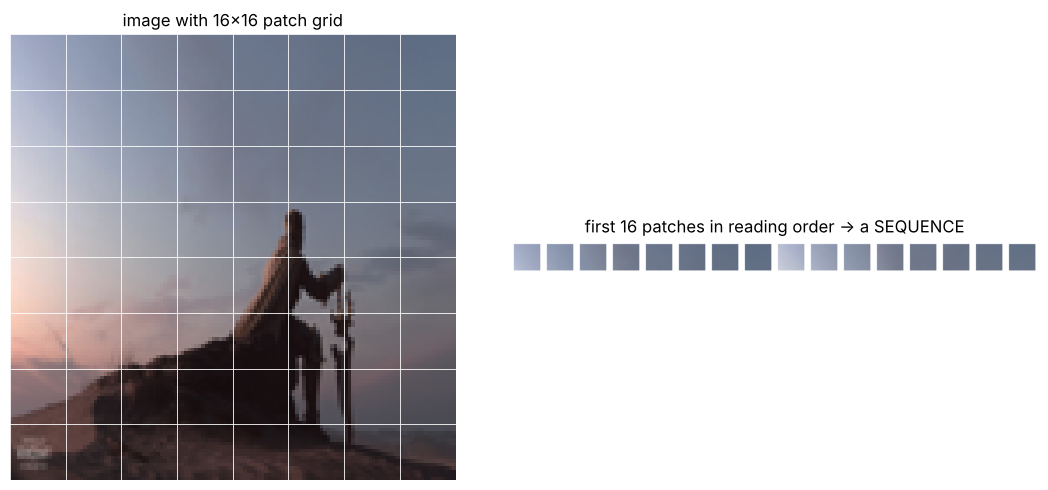

In [2]:
path = "../../week-1/code/sample.jpg"
if os.path.exists(path):
    img = Image.open(path).convert("RGB").resize((128, 128))
else:
    arr = np.ones((128, 128, 3)); arr[32:96, 32:96] = [0.2, 0.6, 0.9]
    img = Image.fromarray((arr * 255).astype(np.uint8))
img_array = np.array(img)

def split_into_patches(image, patch_size):
    # same function as the course notebook: walk the image in patch_size steps
    patches = []
    for i in range(0, image.shape[0], patch_size):
        for j in range(0, image.shape[1], patch_size):
            patches.append(image[i:i + patch_size, j:j + patch_size])
    return np.array(patches)

patch_size = 16
patches = split_into_patches(img_array, patch_size)
tokens = patches.reshape(patches.shape[0], -1)              # flatten every patch into one long vector
print("image shape:", img_array.shape)
print(f"{len(patches)} patches of {patch_size}x{patch_size}x3  ->  token matrix {tokens.shape}  (64 tokens, each 768 numbers)")
print("first token (first 12 values):", tokens[0][:12])

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(img_array); ax[0].set_title("image with 16x16 patch grid"); ax[0].axis("off")
for k in range(0, 129, patch_size):
    ax[0].axhline(k - 0.5, color="white", lw=0.6); ax[0].axvline(k - 0.5, color="white", lw=0.6)
strip = np.concatenate([np.pad(p, ((2, 2), (2, 2), (0, 0)), constant_values=255) for p in patches[:16]], axis=1)
ax[1].imshow(strip); ax[1].set_title("first 16 patches in reading order -> a SEQUENCE"); ax[1].axis("off")
plt.tight_layout(); plt.show()

### Patch size controls the sequence length (course vit2 exercise)

patch  8x8  -> 256 tokens -> attention compares 256x256 = 65,536 pairs
patch 16x16 ->  64 tokens -> attention compares 64x64 =  4,096 pairs


patch 32x32 ->  16 tokens -> attention compares 16x16 =    256 pairs


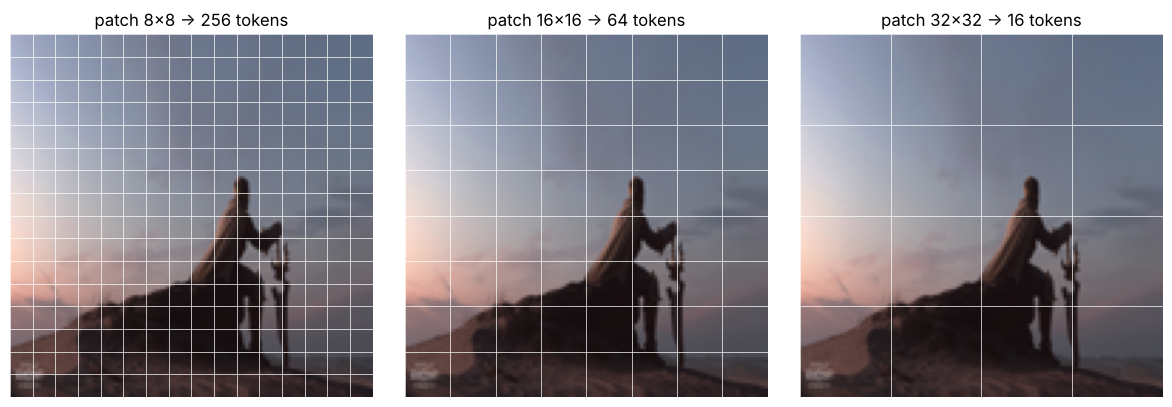

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, ps in zip(ax, [8, 16, 32]):
    n = len(split_into_patches(img_array, ps))
    a.imshow(img_array); a.axis("off")
    for k in range(0, 129, ps):
        a.axhline(k - 0.5, color="white", lw=0.5); a.axvline(k - 0.5, color="white", lw=0.5)
    a.set_title(f"patch {ps}x{ps} -> {n} tokens")
    print(f"patch {ps:>2}x{ps:<2} -> {n:>3} tokens -> attention compares {n}x{n} = {n * n:>6,} pairs")
plt.tight_layout(); plt.show()

**Trade-off:** smaller patches keep more detail but create more tokens, and attention compares **every token with every other**, so the cost grows with the **square** of the token count. Working pixel by pixel (16,384 "tokens" for 128×128) would mean 268 million pairs. **Patches make transformers feasible on images.**

## 2 · Step 2: embeddings, position and the [CLS] token

1. **Patch embedding:** a learned linear layer maps each flattened patch (768 numbers) to a smaller vector (e.g. 64), the "word embedding" of the patch.
2. **Position embedding:** attention itself has **no idea of order**. Shuffle the patches and it gives the same result. So a learned vector per **position** is added, telling the model *where* each patch came from.
3. **[CLS] token:** an extra learned token placed at the start of the sequence. It owns no patch. Through attention it **gathers a summary of the whole image**, and its final value is used for classification ("cat" vs "dog").

## 3 · Step 3: attention, Query, Key and Value (Q19)

Every token produces three vectors through three learned linear layers:

| | Plain meaning | Library analogy |
|---|---|---|
| **Query (Q)** | what am *I* looking for? | your search request |
| **Key (K)** | what do *I* contain or offer? | the label on each book |
| **Value (V)** | the information I'll hand over if picked | the book's content |

**Process:**
1. Compare each Query with every Key (dot product) to get **similarity scores**.
2. Divide by √d (keeps the numbers in a sensible range) and apply **softmax**, so each token's scores become **weights that sum to 1**.
3. Output = the **weighted sum of the Values**. Each token now carries information **mixed in from the tokens it found relevant**.

  **Attention(Q, K, V) = softmax(Q·Kᵀ / √d) · V**

### The course's toy demo (vit2, part 3), explained
The course notebook uses the tokens themselves as Q, K and V (no learned projections), which is the simplest possible attention:

In [4]:
torch.manual_seed(0)
tokens = torch.randn(4, 3)                          # 4 patches, each a 3-number embedding
print("tokens (patch embeddings):\n", tokens.numpy())

scores = tokens @ tokens.T                          # every patch compared with every patch (dot product)
print("\nraw attention scores (4x4):\n", scores.numpy())

weights = torch.softmax(scores, dim=-1)             # each ROW sums to 1
print("\nattention weights (rows sum to 1):\n", weights.numpy(), "\nrow sums:", weights.sum(1).numpy())

attended = weights @ tokens                         # weighted mix of the tokens
print("\nattended representations (each patch now mixes info from the others):\n", attended.numpy())

tokens (patch embeddings):
 [[ 1.54 -0.29 -2.18]
 [ 0.57 -1.08 -1.4 ]
 [ 0.4   0.84 -0.72]
 [-0.4  -0.6   0.18]]

raw attention scores (4x4):
 [[ 7.21  4.24  1.94 -0.84]
 [ 4.24  3.46  0.33  0.16]
 [ 1.94  0.33  1.38 -0.79]
 [-0.84  0.16 -0.79  0.55]]

attention weights (rows sum to 1):
 [[0.95 0.05 0.   0.  ]
 [0.67 0.31 0.01 0.01]
 [0.55 0.11 0.31 0.04]
 [0.11 0.31 0.12 0.46]] 
row sums: [1. 1. 1. 1.]

attended representations (each patch now mixes info from the others):
 [[ 1.49 -0.33 -2.13]
 [ 1.21 -0.52 -1.89]
 [ 1.01 -0.04 -1.56]
 [ 0.21 -0.54 -0.68]]


Read row *i* of the weights as "how much patch *i* listens to each patch". Notice row 2: patch 2 listens more to patch 0 (0.55) than to itself (0.31). A dot product grows with vector **length** as well as direction, so a long vector like token 0 dominates everyone's attention. **Real attention uses three separate learned projections** (W_Q, W_K, W_V), so a token can *ask for* something different from what it *offers*, and the network **learns** which relationships matter.

### The "bank" example: context changes meaning
In language, "**bank**" means different things in "*river bank*" and "*money bank*". Attention lets the "bank" token pull in information from the context word. Below we hand-make tiny 2-D embeddings (dimension 1 = "nature-ness", dimension 2 = "finance-ness") and watch the output for "bank" shift toward its context:

In [5]:
vocab = {"river": [1.0, 0.0], "money": [0.0, 1.0], "the": [0.1, 0.1], "bank": [0.5, 0.5]}
W_q = torch.eye(2) * 3; W_k = torch.eye(2) * 3; W_v = torch.eye(2)       # simple "learned" projections

def attend(sentence):
    X = torch.tensor([vocab[w] for w in sentence])
    Q, K, V = X @ W_q, X @ W_k, X @ W_v
    A = torch.softmax(Q @ K.T / np.sqrt(2), dim=-1)
    return A, A @ V

for sentence in [["the", "river", "bank"], ["the", "money", "bank"]]:
    A, out = attend(sentence)
    b = sentence.index("bank")
    weights = {w: round(float(v), 2) for w, v in zip(sentence, A[b])}
    print(f"{' '.join(sentence):<16} 'bank' attends to {weights}"
          f" -> new 'bank' vector {out[b].numpy()}  (nature, finance)")

the river bank   'bank' attends to {'the': 0.04, 'river': 0.48, 'bank': 0.48} -> new 'bank' vector [0.73 0.24]  (nature, finance)
the money bank   'bank' attends to {'the': 0.04, 'money': 0.48, 'bank': 0.48} -> new 'bank' vector [0.24 0.73]  (nature, finance)


Same word, same starting vector [0.5, 0.5], but after attention "bank" leans toward **nature** in one sentence and **finance** in the other. In a ViT the same thing happens with patches: a patch of stripes can attend to other stripe patches far away and "realise" it's part of a zebra.

## 4 · Why patches + attention capture global context (Q20)
1. **The image becomes a sequence:** patches act like words, so the transformer can relate any two regions.
2. **Long-range dependencies from layer 1:** a CNN neuron in the first layer sees 3×3 pixels, and it takes many layers before distant regions meet. With attention, the top-left patch can directly attend to the bottom-right patch **in the very first layer**.
3. **Reduced complexity:** patches shorten the sequence enough to make attention affordable.
4. **Local and global together:** each patch embedding keeps **local** detail (edges, texture inside the patch), and attention across patches builds the **global** picture (object shape, scene layout).

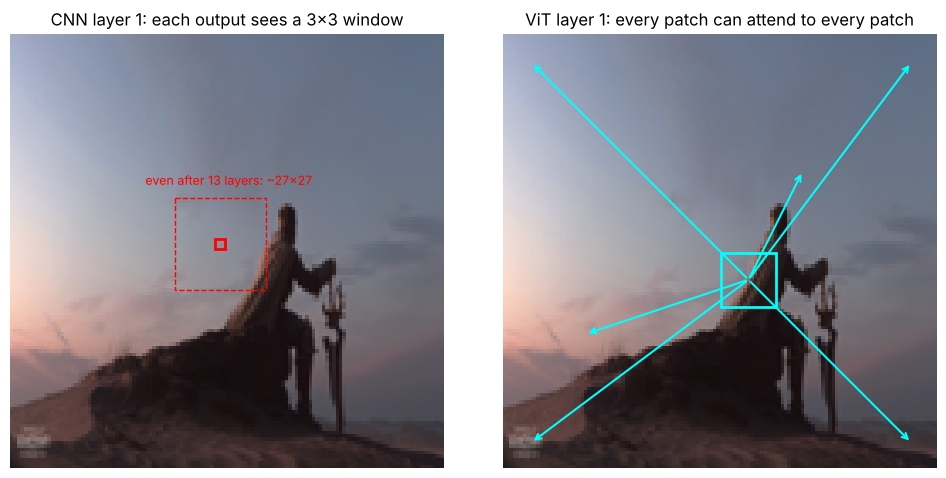

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.8))
ax[0].imshow(img_array); ax[0].set_title("CNN layer 1: each output sees a 3x3 window"); ax[0].axis("off")
ax[0].add_patch(mpatches.Rectangle((60, 60), 3, 3, fill=False, ec="red", lw=2))
ax[0].add_patch(mpatches.Rectangle((48, 48), 27, 27, fill=False, ec="red", lw=1, ls="--"))
ax[0].text(64, 44, "even after 13 layers: ~27x27", color="red", ha="center", fontsize=9)
ax[1].imshow(img_array); ax[1].set_title("ViT layer 1: every patch can attend to every patch"); ax[1].axis("off")
centre = (72, 72)
for (r, c) in [(0, 0), (0, 7), (7, 0), (7, 7), (2, 5), (5, 1)]:
    ax[1].annotate("", xy=(c * 16 + 8, r * 16 + 8), xytext=centre, arrowprops=dict(arrowstyle="->", color="cyan", lw=1.5))
ax[1].add_patch(mpatches.Rectangle((64, 64), 16, 16, fill=False, ec="cyan", lw=2))
plt.tight_layout(); plt.show()

## 5 · Build and train a tiny Vision Transformer

Our ViT, sized for a laptop: 16×16 digit images → **4×4 patches = 16 tokens** + [CLS], embedding size 64, **2 transformer blocks** with 4 attention heads. Each block is:

```
x ─► LayerNorm ─► multi-head attention ─(+ skip)─► LayerNorm ─► MLP ─(+ skip)─►
```

Notice the **skip (residual) connections**: they're straight from ResNet (notebook 03). **Multi-head** means several attention "heads" run in parallel, each free to learn a different kind of relationship.

In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = F.interpolate(torch.tensor(digits.images, dtype=torch.float32)[:, None] / 16, size=(16, 16), mode="bilinear", align_corners=False)
y = torch.tensor(digits.target)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

class Block(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=0.1, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * 2), nn.GELU(), nn.Dropout(0.1), nn.Linear(dim * 2, dim))
        self.last_attention = None
    def forward(self, x):
        h = self.norm1(x)
        a, w = self.attn(h, h, h, need_weights=True)        # Q, K and V all come from the tokens
        self.last_attention = w.detach()                    # (batch, tokens, tokens), averaged over heads
        x = x + a                                           # residual connection
        return x + self.mlp(self.norm2(x))                  # residual connection

class TinyViT(nn.Module):
    def __init__(self, patch=4, dim=64, depth=2, heads=4, n_classes=10):
        super().__init__()
        self.patch = patch
        n_patches = (16 // patch) ** 2
        self.embed = nn.Linear(patch * patch, dim)                          # patch embedding
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))                     # [CLS] token
        self.pos = nn.Parameter(torch.randn(1, n_patches + 1, dim) * 0.02)  # position embeddings
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, n_classes)
    def forward(self, x):
        B = x.shape[0]
        p = x.unfold(2, self.patch, self.patch).unfold(3, self.patch, self.patch)   # cut into 4x4 patches
        p = p.reshape(B, -1, self.patch * self.patch)                               # (B, 16 tokens, 16 values)
        t = torch.cat([self.cls.expand(B, -1, -1), self.embed(p)], dim=1) + self.pos
        for blk in self.blocks:
            t = blk(t)
        return self.head(self.norm(t)[:, 0])                                        # classify from [CLS]

def small_cnn():
    return nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(64 * 16, 64), nn.ReLU(), nn.Linear(64, 10))

def fit(model, epochs=40):
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=0.05)
    for _ in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 64):
            idx = perm[i:i + 64]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return (model(Xte).argmax(1) == yte).float().mean().item()

results = {}
for name, make in [("Tiny ViT", TinyViT), ("Small CNN", small_cnn)]:
    torch.manual_seed(0)
    model = make()
    t = time.time(); acc = fit(model)
    results[name] = model
    print(f"{name:<10} parameters {sum(p.numel() for p in model.parameters()):>7,}   test accuracy {acc:.1%}   ({time.time() - t:.0f} s)")
vit = results["Tiny ViT"]

Tiny ViT   parameters  69,962   test accuracy 96.9%   (13 s)


Small CNN  parameters  85,066   test accuracy 98.1%   (5 s)


**The ViT learns, but the similar-sized CNN wins on this small dataset.** That's expected and worth remembering. A CNN has a built-in assumption ("nearby pixels belong together, and patterns can appear anywhere"), which is exactly right for images and saves it from learning that from data. A ViT has to **learn** such relationships, so it needs **much more data**. The original ViT only beat the best CNNs after pretraining on hundreds of millions of images. That's the "**scales well with large datasets**" benefit in the notes.

### What does the [CLS] token look at?
The attention weights from [CLS] to the 16 patches, in the last block, show which parts of the digit the model consulted:

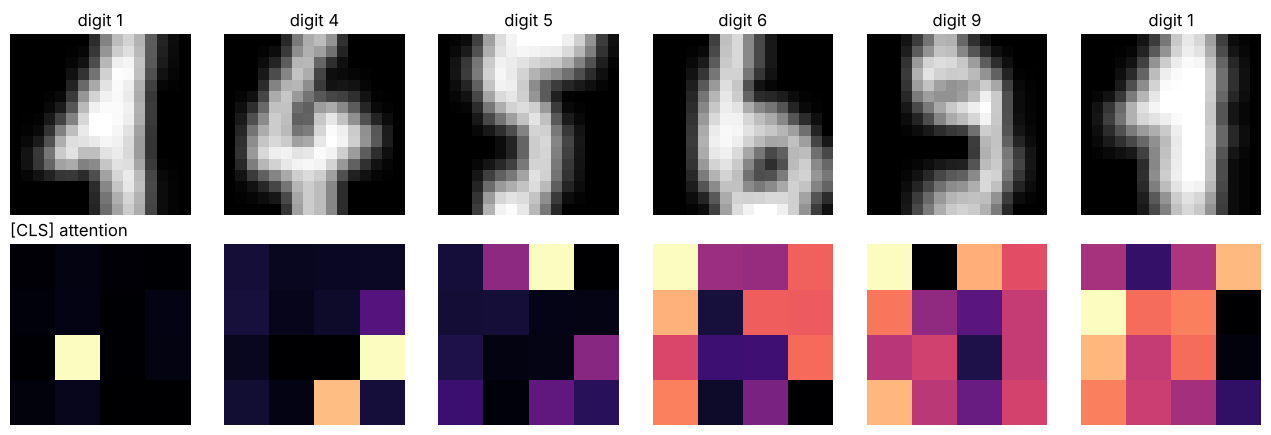

In [8]:
with torch.no_grad():
    vit(Xte[:6])
cls_attn = vit.blocks[-1].last_attention[:, 0, 1:]          # row 0 = [CLS]; skip its attention to itself
fig, ax = plt.subplots(2, 6, figsize=(13, 4.4))
for k in range(6):
    ax[0, k].imshow(Xte[k, 0], cmap="gray"); ax[0, k].set_title(f"digit {int(yte[k])}"); ax[0, k].axis("off")
    ax[1, k].imshow(cls_attn[k].reshape(4, 4), cmap="magma"); ax[1, k].axis("off")
ax[1, 0].set_title("[CLS] attention", loc="left")
plt.tight_layout(); plt.show()

Bright cells are the patches [CLS] drew information from in the last block. For some digits the attention is sharply focused on one or two patches of the stroke. For others it's spread widely, background included, because the earlier block has already mixed information between patches, so a "background" token may by now carry stroke information. Attention maps of real ViTs are similarly suggestive but not a perfect explanation of the model. The key point: the model chooses **where to look** by itself, with no convolution anywhere.

## 6 · Benefits, applications and the big picture

**Benefits:** captures **global context** better than CNNs · **scales well** with large datasets · flexible (classification, detection, segmentation) · inspired **hybrid** CNN + Transformer models.
**Applications:** image classification (ImageNet benchmarks) · medical imaging (global patterns across a scan) · video understanding (adding attention across time) · multimodal vision + language (image captioning, CLIP-style search).
**Impact:** shifted computer vision from **CNN-centric** to **transformer-centric** approaches.

### From LeNet to ViT (Hard Q10)
| Step | What it contributed to ViT |
|---|---|
| **LeNet** | learning features end to end from pixels (no hand-made features) |
| **AlexNet** | scale: big data (ImageNet) + GPUs + ReLU/dropout made big models trainable |
| **VGG** | depth and simple, repeated building blocks |
| **ResNet** | **residual connections** (in every transformer block) and very deep training; normalization |
| **EfficientNet** | systematic thinking about **scaling** model and data size |
| **ViT** | keeps the deep, residual, scaled-up recipe but swaps local convolution for **global attention** over patches |

---
## ✅ Check yourself
1. Purpose of Query, Key and Value? *(Query = what a token looks for; Key = what each token offers; Value = information passed on; output = weights from Q·K, applied to V)*
2. Why split an image into patches? *(turns the image into a token sequence, keeps the sequence short enough for attention, and lets distant regions interact directly, giving global context)*
3. What is the [CLS] token for? *(a learned summary token whose final value is used for classification)*
4. Why add position embeddings? *(attention ignores order; positions tell the model where each patch was)*
5. Why might a CNN beat a ViT on a small dataset? *(the CNN's built-in locality assumption; ViTs must learn it from lots of data)*
6. Patch size 16 on a 224×224 image gives how many tokens? *((224/16)² = 196, plus [CLS] = 197)*